# 6주차 실습: 이진 트리 구조 설계 및 순회 — 학생용

## 실습 목표 및 규약
TreeNode/BinaryTree 설계, 재귀 DFS 3종, 반복 전위, 큐 기반 BFS, 높이·노드·리프 수를 구현한다.
- Python 3.8+ / Jupyter 또는 Colab. 위에서 아래 순서로 실행한다.
- 루트 깊이 0, 리프 높이 0, 빈 트리 높이 -1: **간선 수 기준**.
- 일반 이진 트리는 BST가 아니다. 중위 순회가 항상 정렬되는 것은 아니다.
- 이 실습의 구조는 사이클·공유 자식 없는 트리라고 가정한다.
- `BinaryTree(None)`은 빈 트리를 뜻한다. None 값을 가진 루트는 `tree.root = TreeNode(None)`으로 생성한다.


In [2]:
from collections import deque
print("실습 환경 준비 완료")

실습 환경 준비 완료


## Step 1. TreeNode
데이터와 왼쪽/오른쪽 자식 참조를 저장합니다.

In [3]:
class TreeNode:
    def __init__(self, data):
        # TODO: data, left, right 초기화 (자식은 None)
        self.data = data
        self.left = None
        self.right= None

    def __repr__(self):
        return f"TreeNode({self.data!r})"

## Step 2. BinaryTree
전위 NLR / 중위 LNR / 후위 LRN. 재귀는 None에서 종료. 반복 전위는 오른쪽 먼저 push.

In [4]:
class BinaryTree:
    def __init__(self, root_data=None):
        # TODO: root_data가 None이면 빈 트리, 아니면 TreeNode 생성
        if root_data is None:
          self.root = None
        else:
          self.root = TreeNode(root_data)

    def preorder(self):
        # TODO: None 종료 → 현재 노드 → 왼쪽 → 오른쪽
        result = []
        def _preorder(node):
          if node is not None:
            result.append(node.data)
            _preorder(node.left)
            _preorder(node.right)
        _preorder(self.root)
        return result


    def inorder(self):
        # TODO: None 종료 → 왼쪽 → 현재 노드 → 오른쪽
        result = []
        def _inorder(node):
          if node is not None:
            _inorder(node.left)
            result.append(node.data)
            _inorder(node.right)
        _inorder(self.root)
        return result

    def postorder(self):
        # TODO: None 종료 → 왼쪽 → 오른쪽 → 현재 노드
        result = []
        def _postorder(node):
          if node is not None:
            _postorder(node.left)
            _postorder(node.right)
            result.append(node.data)
        _postorder(self.root)
        return result

    def preorder_iterative(self):
        # TODO: 스택에서 pop 후 방문; 오른쪽 자식을 먼저 push
        if self.root is None:
          return []

        result =[]
        stack = [self.root]
        while stack:
          curr = stack.pop()
          result.append(curr.data)
          if curr.right:
            stack.append(curr.right)
          if curr.left:
            stack.append(curr.left)

        return result

    def levelorder(self):
        # TODO: deque.popleft 후 방문; 왼쪽, 오른쪽 순으로 enqueue
        if self.root is None:
          return []

        result = []
        queue = deque([self.root])
        while queue:
          curr = queue.popleft()
          result.append(curr.data)
          if curr.left: queue.append(curr.left)
          if curr.right: queue.append(curr.right)
        return result

    def height(self):
        # TODO: 빈 노드 -1; 1 + max(왼쪽 높이, 오른쪽 높이)
        def _height(node):
          if node is None:
            return -1
          return 1 + max(_height(node.left), _height(node.right))

        return _height(self.root)

    def count_nodes(self):
        # TODO: 빈 노드 0; 1 + 왼쪽 노드 수 + 오른쪽 노드 수
        def _count(node):
            if node is None:
                return 0
            return 1 + _count(node.left) + _count(node.right)
        return _count(self.root)

    def count_leaves(self):
        # TODO: 빈 노드 0; 자식 없는 노드 1; 나머지는 좌우 합
        def _count_leaf(node):
            if node is None:
                return 0
            # 자식이 없는 단말(Leaf) 노드인 경우
            if node.left is None and node.right is None:
                return 1
            return _count_leaf(node.left) + _count_leaf(node.right)
        return _count_leaf(self.root)



## Step 3. 예시 트리
```text
      A
    /   \
   B     C
  / \     \
 D   E     F
```

In [5]:
tree = BinaryTree("A")
tree.root.left = TreeNode("B")
tree.root.right = TreeNode("C")
tree.root.left.left = TreeNode("D")
tree.root.left.right = TreeNode("E")
tree.root.right.right = TreeNode("F")

## Step 4. 결과 및 경계 사례 검증

In [6]:
expected = {
    "preorder": ["A", "B", "D", "E", "C", "F"],
    "inorder": ["D", "B", "E", "A", "C", "F"],
    "postorder": ["D", "E", "B", "F", "C", "A"],
    "levelorder": ["A", "B", "C", "D", "E", "F"]
}
for method, answer in expected.items():
    actual = getattr(tree, method)()
    print(method, actual)
    assert actual == answer
assert tree.preorder_iterative() == tree.preorder()
assert (tree.height(), tree.count_nodes(), tree.count_leaves()) == (2, 6, 3)
print("예시 트리 테스트 통과")


preorder ['A', 'B', 'D', 'E', 'C', 'F']
inorder ['D', 'B', 'E', 'A', 'C', 'F']
postorder ['D', 'E', 'B', 'F', 'C', 'A']
levelorder ['A', 'B', 'C', 'D', 'E', 'F']
예시 트리 테스트 통과


In [7]:
for t, sequence, height, leaves in [
    (BinaryTree(), [], -1, 0),
    (BinaryTree("X"), ["X"], 0, 1),
]:
    for method in ["preorder", "inorder", "postorder", "levelorder", "preorder_iterative"]:
        assert getattr(t, method)() == sequence
    assert (t.height(), t.count_nodes(), t.count_leaves()) == (height, len(sequence), leaves)

skew = BinaryTree(1)
skew.root.right = TreeNode(2)
skew.root.right.right = TreeNode(3)
assert skew.preorder() == skew.inorder() == skew.levelorder() == [1, 2, 3]
assert skew.postorder() == [3, 2, 1]
assert skew.preorder_iterative() == [1, 2, 3]
assert (skew.height(), skew.count_nodes(), skew.count_leaves()) == (2, 3, 1)
print("빈 트리 / 단일 노드 / 편향 트리 테스트 통과")


빈 트리 / 단일 노드 / 편향 트리 테스트 통과


## Step 5. VisuAlgo 시각화 및 검증
[VisuAlgo BST](https://visualgo.net/en/bst)는 **BST 시각화**이며 임의의 A~F 이진 트리를 직접 만드는 도구라고 가정하지 않습니다.
1. BST 모드에서 빈 트리에 **4, 2, 6, 1, 3, 7** 순서로 삽입합니다(자동 균형 모드와 구별).
2. A→4, B→2, C→6, D→1, E→3, F→7 대응으로 위 예시와 구조를 비교합니다.
3. 화면에서 제공되는 순회 기능은 애니메이션으로 검증하고, 미지원 순회는 그림 위에 방문 번호를 적어 검증합니다.
4. 아래 코드 결과와 수동 trace를 비교하고 캡처와 설명을 기록하세요. **BST 삽입은 다음 주 내용이며 이번에는 구조 관찰만 합니다.**


In [8]:
numeric = BinaryTree(4)
numeric.root.left = TreeNode(2)
numeric.root.right = TreeNode(6)
numeric.root.left.left = TreeNode(1)
numeric.root.left.right = TreeNode(3)
numeric.root.right.right = TreeNode(7)
assert numeric.preorder() == [4, 2, 1, 3, 6, 7]
assert numeric.inorder() == [1, 2, 3, 4, 6, 7]
assert numeric.postorder() == [1, 3, 2, 7, 6, 4]
assert numeric.levelorder() == [4, 2, 6, 1, 3, 7]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(numeric, method)())


preorder [4, 2, 1, 3, 6, 7]
inorder [1, 2, 3, 4, 6, 7]
postorder [1, 3, 2, 7, 6, 4]
levelorder [4, 2, 6, 1, 3, 7]


## 복잡도 분석
n=노드 수, h=간선 기준 높이, w=최대 레벨 너비.

|연산|시간|보조 공간(출력 제외)|
|---|---|---|
|재귀 DFS 3종 / 반복 전위|O(n)|O(h+1)|
|큐 기반 레벨 순회|O(n)|O(w)|
|높이·노드 수·리프 수|O(n)|O(h+1)|
|완전 트리 구성|O(n)|O(n) 큐 + O(n) 생성 노드|

순회 반환 리스트는 별도 O(n) 공간입니다. 균형 트리는 h=O(log n), 편향 트리는 h=O(n). 깊은 편향 트리의 재귀는 Python 재귀 깊이 제한에 걸릴 수 있습니다. BFS도 깊이별 수집으로 재귀 구현 가능하지만 큐 기반 반복이 자연스럽습니다.


## 제출 과제: 이진 트리 순회 프로그램
1. build_complete_tree(values)를 구현하고 네 가지 순회 결과 출력.
2. 빈/단일/완전/편향 트리 테스트 및 시간·공간 복잡도 설명.
3. 시각화 캡처와 방문 순서 검증 설명 첨부.
4. 개인 GitHub의 Week6 폴더에 노트북/설명 저장. 계획서대로 주당 최소 2회 커밋, 과제 폼에 GitHub 링크 제출.

주의: 아래 TODO를 구현하기 전 학생용 테스트 실패는 정상입니다. 미구현 셀은 무한 반복 대신 NotImplementedError로 즉시 중단합니다.


In [9]:
def build_complete_tree(values):
    # TODO: 빈 입력 처리. 큐로 부모를 꺼내 left/right를 순서대로 채우세요.
    # 입력은 리스트이며 None도 실제 데이터 값입니다.
    if not values:
        return BinaryTree()

    tree = BinaryTree()
    tree.root = TreeNode(values[0])

    queue = deque([tree.root])
    i = 1
    while i < len(values):
        parent = queue.popleft()
        if i < len(values):
            parent.left = TreeNode(values[i])
            queue.append(parent.left)
            i += 1
        if i < len(values):
            parent.right = TreeNode(values[i])
            queue.append(parent.right)
            i += 1

    return tree

In [10]:
complete = build_complete_tree([1, 2, 3, 4, 5, 6, 7])
assert complete.preorder() == [1, 2, 4, 5, 3, 6, 7]
assert complete.inorder() == [4, 2, 5, 1, 6, 3, 7]
assert complete.postorder() == [4, 5, 2, 6, 7, 3, 1]
assert complete.levelorder() == [1, 2, 3, 4, 5, 6, 7]
assert complete.preorder_iterative() == complete.preorder()
assert build_complete_tree([]).height() == -1
assert build_complete_tree([9]).levelorder() == [9]
assert build_complete_tree([1, 2, 3, 4]).levelorder() == [1, 2, 3, 4]
assert build_complete_tree([None, 2]).levelorder() == [None, 2]
for method in ["preorder", "inorder", "postorder", "levelorder"]:
    print(method, getattr(complete, method)())
print("과제 테스트 통과")


preorder [1, 2, 4, 5, 3, 6, 7]
inorder [4, 2, 5, 1, 6, 3, 7]
postorder [4, 5, 2, 6, 7, 3, 1]
levelorder [1, 2, 3, 4, 5, 6, 7]
과제 테스트 통과


## 2. 테스트 및 시간·공간 복잡도

빈 입력과 단일 입력은 생성 함수부터 검증했다. 7개 노드는 모든 층이 찬 포화 이진 트리이며 완전 이진 트리이기도 하다. 6개 노드는 마지막 층이 왼쪽부터 채워지는 일반적인 완전 이진 트리를 검증한다. 편향 트리는 생성 함수로 만들 수 없으므로 자식 참조를 직접 연결해 좌·우 두 방향을 검사했다. None은 빈 자리 표시가 아닌 실제 데이터로 검증했다.

각 사례에서 네 순회의 **직접 작성한 기대값**, 반복 전위, 높이·노드·리프 수를 assert로 검사한다. 높이는 간선 기준이며 빈 트리는 -1, 단일 트리는 0이다.

n은 노드 수, h는 간선 기준 높이, w는 최대 레벨 너비다. 아래는 n ≥ 1 기준이며 빈 입력의 시간·공간은 O(1)이다.

|연산|시간|보조 공간: 입력과 반환 결과 제외|반환 결과 공간|
|---|---|---|---|
|build_complete_tree|O(n)|O(n): 부모 큐|O(n): 생성된 노드|
|재귀 전위·중위·후위|O(n)|O(h+1): 재귀 호출 스택|O(n): 방문 리스트|
|반복 전위|O(n)|O(h+1) 상한: 명시적 스택|O(n)|
|레벨 순회|O(n)|O(w): 큐|O(n)|
|높이·노드 수·리프 수|각 O(n)|O(h+1)|O(1)|

각 노드는 한 번 방문하고 큐의 append/popleft는 O(1)이므로 생성과 순회는 O(n)이다. 반복 전위도 각 노드를 한 번 push/pop한다. 반환 리스트를 포함하면 모든 순회의 전체 추가 공간은 O(n)이다.

완전 트리는 h=O(log n), w=O(n)이므로 재귀 DFS 보조 공간은 O(log n), BFS는 O(n)이다. 편향 트리는 h=n-1, w=1이므로 재귀 DFS는 O(n), BFS는 O(1)이다. **현재 반복 전위 구현은 한 방향 편향 트리에서 스택에 최대 한 노드만 남으므로 O(1)**이다. 깊은 편향 트리에서는 재귀 순회와 통계 함수가 Python 재귀 깊이 제한에 걸릴 수 있다.


In [12]:
# 기대 순서는 순회 함수를 호출하지 않고 트리 구조에서 직접 작성했다.
def make_skew(values, side):
    t = BinaryTree()
    if not values:
        return t
    t.root = TreeNode(values[0])
    node = t.root
    for value in values[1:]:
        child = TreeNode(value)
        setattr(node, side, child)
        node = child
    return t

methods = ['preorder', 'inorder', 'postorder', 'levelorder']
cases = [
    ('빈 트리', build_complete_tree([]), [[], [], [], []], (-1, 0, 0)),
    ('단일 트리', build_complete_tree([9]), [[9], [9], [9], [9]], (0, 1, 1)),
    ('완전 트리 7개', build_complete_tree([1,2,3,4,5,6,7]),
     [[1,2,4,5,3,6,7], [4,2,5,1,6,3,7], [4,5,2,6,7,3,1], [1,2,3,4,5,6,7]], (2,7,4)),
    ('완전 트리 6개', build_complete_tree([1,2,3,4,5,6]),
     [[1,2,4,5,3,6], [4,2,5,1,6,3], [4,5,2,6,3,1], [1,2,3,4,5,6]], (2,6,3)),
    ('오른쪽 편향', make_skew([1,2,3,4], 'right'),
     [[1,2,3,4], [1,2,3,4], [4,3,2,1], [1,2,3,4]], (3,4,1)),
    ('왼쪽 편향', make_skew([1,2,3,4], 'left'),
     [[1,2,3,4], [4,3,2,1], [4,3,2,1], [1,2,3,4]], (3,4,1)),
]
for name, t, expected_orders, stats in cases:
    print('\n[' + name + ']')
    for method, expected_order in zip(methods, expected_orders):
        actual = getattr(t, method)()
        assert actual == expected_order, (name, method, actual, expected_order)
        print(method, actual)
    assert t.preorder_iterative() == expected_orders[0]
    assert (t.height(), t.count_nodes(), t.count_leaves()) == stats
    print('높이 / 노드 / 리프:', stats, 'PASS')



[빈 트리]
preorder []
inorder []
postorder []
levelorder []
높이 / 노드 / 리프: (-1, 0, 0) PASS

[단일 트리]
preorder [9]
inorder [9]
postorder [9]
levelorder [9]
높이 / 노드 / 리프: (0, 1, 1) PASS

[완전 트리 7개]
preorder [1, 2, 4, 5, 3, 6, 7]
inorder [4, 2, 5, 1, 6, 3, 7]
postorder [4, 5, 2, 6, 7, 3, 1]
levelorder [1, 2, 3, 4, 5, 6, 7]
높이 / 노드 / 리프: (2, 7, 4) PASS

[완전 트리 6개]
preorder [1, 2, 4, 5, 3, 6]
inorder [4, 2, 5, 1, 6, 3]
postorder [4, 5, 2, 6, 3, 1]
levelorder [1, 2, 3, 4, 5, 6]
높이 / 노드 / 리프: (2, 6, 3) PASS

[오른쪽 편향]
preorder [1, 2, 3, 4]
inorder [1, 2, 3, 4]
postorder [4, 3, 2, 1]
levelorder [1, 2, 3, 4]
높이 / 노드 / 리프: (3, 4, 1) PASS

[왼쪽 편향]
preorder [1, 2, 3, 4]
inorder [4, 3, 2, 1]
postorder [4, 3, 2, 1]
levelorder [1, 2, 3, 4]
높이 / 노드 / 리프: (3, 4, 1) PASS


### 3. 시각화 및 방문 순서 검증

BST에 4, 2, 6, 1, 3, 7을 순서대로 삽입한 구조를
노트북의 numeric 트리와 비교하였다.

- 전위: 루트 → 왼쪽 → 오른쪽
  - 4 → 2 → 1 → 3 → 6 → 7
- 중위: 왼쪽 → 루트 → 오른쪽
  - 1 → 2 → 3 → 4 → 6 → 7
- 후위: 왼쪽 → 오른쪽 → 루트
  - 1 → 3 → 2 → 7 → 6 → 4
- 레벨: 위에서 아래로, 같은 층에서는 왼쪽부터
  - 4 → 2 → 6 → 1 → 3 → 7

그림에서 구한 방문 순서를 Python 순회 출력과 비교하여
네 가지 결과가 일치하는지 확인하였다.

이 시각화는 numeric 트리를 검증한 것이며,
build_complete_tree([1, 2, 3, 4, 5, 6, 7])로 만든 트리와는
구조 및 데이터 배치가 다르다.

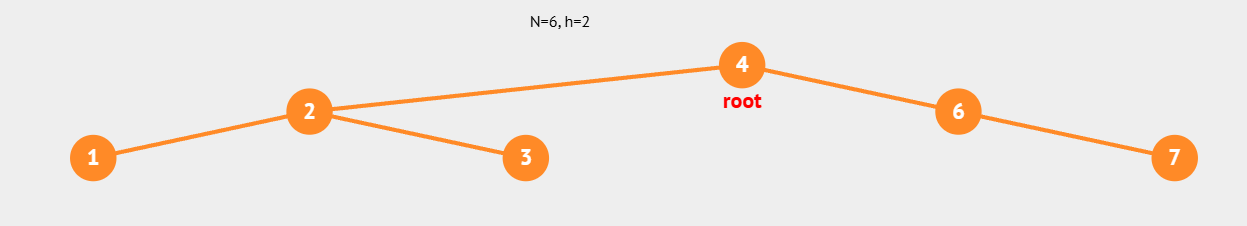